# Per-active-user LLM cost model (CDES)

Parameterized model estimating **LLM cost per active user per month**, using provider pricing for **cached vs uncached tokens** (OpenAI, Anthropic, Google).

> Edit the parameters in the **1. Parameters** cell, then run all cells. Outputs:
> - `results.json`
> - a compact cost table plus a line chart of cost vs cache hit rate at 10% / 50% / 90% (also 30% / 70%).


## 1. Parameters

All tunable inputs. Change the values in `params` (below) and re-run.


In [1]:

# 1. PARAMETERS  (edit here, then re-run)
params = {
    "requests_per_user_month": 60,              # AI calls per active user / month
    "cacheable_prefix_tokens": 1800,            # system prompt + KB/RAG context (caching serves this)
    "non_cacheable_remainder_tokens": 1400,     # history + current message (not cacheable)
    "output_tokens": 600,                       # main response output tokens
    "followup_out_mult": 0.15,                  # follow-up generation extra output (fraction of O)
    "cache_rates": [0.10, 0.30, 0.50, 0.70, 0.90],  # hit-rate scenarios (h applies to the prefix)

    # Provider pricing per 1M tokens: input, output, cache-write multiplier, cache-hit multiplier
    "providers": {
        "openai_gpt4o":  {"label": "OpenAI gpt-4o",  "input": 2.50, "output": 10.00, "write_mul": 1.25, "cache_hit_mult": 0.5},
        "anthropic_claude": {"label": "Anthropic Claude 3.5 Sonnet", "input": 3.00, "output": 15.00, "write_mul": 1.25, "cache_hit_mult": 0.1},
        "google_gemini": {"label": "Google Gemini 1.5/2.0-flash", "input": 0.30, "output": 2.50, "write_mul": 1.25, "cache_hit_mult": 0.1},
    },
}


## 2. Model definition

Per active user per month:

```
cost_per_user = R * [ input_cost(h) + output_cost ]
input_cost(h) = [ h*C*CI + (1-h)*C*IW + Rpt*II ] / 1e6
output_cost   = O * followup_out_mult * CO / 1e6
```

`h` = cache hit rate on the cacheable prefix `C`; `CI = II * cache_hit_mult`; `IW = II * write_mul`.


In [2]:

def cost_model(params):
    R = params["requests_per_user_month"]
    C = params["cacheable_prefix_tokens"]
    Rpt = params["non_cacheable_remainder_tokens"]
    O = params["output_tokens"]
    ffu = params["followup_out_mult"]
    rows_out = {}
    for prov, p in params["providers"].items():
        II = p["input"]; CO = p["output"]; IW = II * p["write_mul"]; CI = II * p["cache_hit_mult"]
        rows = []
        for h in params["cache_rates"]:
            cached_in  = h * C                 # tokens read from cache
            written    = (1 - h) * C           # tokens rewritten on a cache miss
            uncached   = Rpt                   # dynamic remainder, always at II
            input_cost = (cached_in * CI + written * IW + uncached * II) / 1e6
            out_cost   = (O * ffu) * CO / 1e6
            rows.append({
                "cache_rate": h,
                "input_cost_usd": input_cost,
                "output_cost_usd": out_cost,
                "total_per_call_usd": input_cost + out_cost,
                "per_user_month_usd": R * (input_cost + out_cost),
                "cached_tokens": cached_in,
                "written_tokens": written,
                "uncached_tokens": uncached,
            })
        rows_out[prov] = rows
    return rows_out


## 3. Run the scenarios & plot

Computes cost per active user/month at 10% / 50% / 90% (plus 30/70) for all providers, prints the table, and plots cost vs cache hit rate.


Provider                  hit       input    output   per-call  per-user/mo
OpenAI gpt-4o             10%     $0.0088   $0.0009    $0.0097      $0.5813
OpenAI gpt-4o             50%     $0.0074   $0.0009    $0.0083      $0.5002
OpenAI gpt-4o             90%     $0.0061   $0.0009    $0.0070      $0.4193
Anthropic Claude 3.5 Sonnet  10%     $0.0103   $0.0014    $0.0117      $0.7007
Anthropic Claude 3.5 Sonnet  50%     $0.0078   $0.0014    $0.0092      $0.5517
Anthropic Claude 3.5 Sonnet  90%     $0.0054   $0.0014    $0.0067      $0.4027
Google Gemini 1.5/2.0-flash  10%     $0.0010   $0.0002    $0.0013      $0.0755
Google Gemini 1.5/2.0-flash  50%     $0.0008   $0.0002    $0.0010      $0.0606
Google Gemini 1.5/2.0-flash  90%     $0.0005   $0.0002    $0.0008      $0.0457

Saved results.json


Saved cost_vs_cache_rate.png


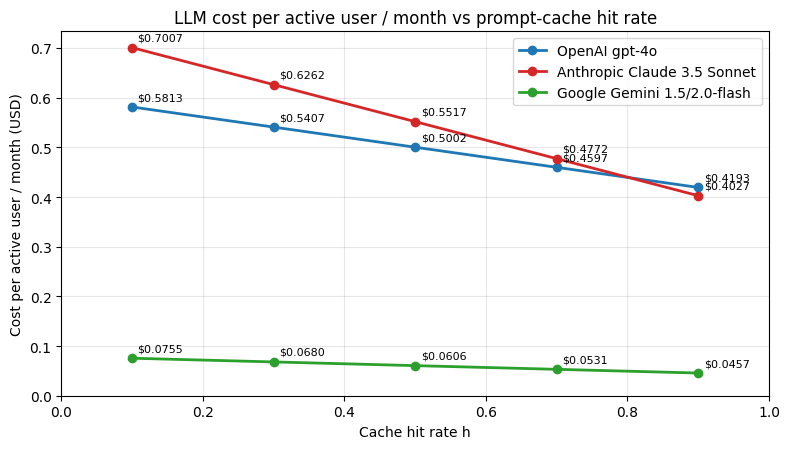

In [3]:

import json

results = cost_model(params)

def money(x): return f"${x:,.4f}"

print(f"{'Provider':<24}{'hit':>5}   {'input':>9}  {'output':>8}  {'per-call':>9}  {'per-user/mo':>11}")
for prov, rows in results.items():
    for row in rows:
        if row["cache_rate"] in (0.10, 0.50, 0.90):
            label = params["providers"][prov]["label"]
            print(f"{label:<24}{int(row['cache_rate']*100):>4}%   "
                  f"{money(row['input_cost_usd']):>9}  {money(row['output_cost_usd']):>8}  "
                  f"{money(row['total_per_call_usd']):>9}  {money(row['per_user_month_usd']):>11}")

with open("results.json", "w") as f:
    json.dump({"params": params, "results": results}, f, indent=2)
print("\nSaved results.json")

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.6))
colors = {"openai_gpt4o": "#1f77b4", "anthropic_claude": "#d62728", "google_gemini": "#2ca02c"}
for prov, rows in results.items():
    rates   = [r["cache_rate"] for r in rows]
    costs   = [r["per_user_month_usd"] for r in rows]
    ax.plot(rates, costs, marker="o", label=params["providers"][prov]["label"], color=colors[prov], lw=2)
    for r_, c_ in zip(rates, costs):
        ax.annotate(money(c_), (r_, c_), textcoords="offset points", xytext=(4, 5), fontsize=8)

ax.set_xlabel("Cache hit rate h")
ax.set_ylabel("Cost per active user / month (USD)")
ax.set_title("LLM cost per active user / month vs prompt-cache hit rate")
ax.set_xlim(0, 1); ax.set_ylim(bottom=0)
ax.grid(alpha=0.3); ax.legend(); ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.savefig("cost_vs_cache_rate.png", dpi=130)
print("Saved cost_vs_cache_rate.png")


## 4. Results (default run)

At `requests_per_user_month=60`, `cacheable_prefix_tokens=1800`, `non_cacheable_remainder_tokens=1400`, `output_tokens=600`, `followup_out_mult=0.15`:

| Provider | 10% h | 50% h | 90% h | saving @90% vs 10% |
|----------|-------|-------|-------|--------------------|
| OpenAI gpt-4o | $0.5813 | $0.5002 | $0.4193 | $0.1620 |
| Anthropic Claude 3.5 Sonnet | $0.7007 | $0.5517 | $0.4027 | $0.2981 |
| Google Gemini 1.5/2.0-flash | $0.0755 | $0.0606 | $0.0457 | $0.0298 |


### Outputs produced

- `results.json` — full model output (every scenario, per-call and per-user-per-month).
- `cost_vs_cache_rate.png` — line chart of cost vs cache hit rate.

### Notes

- OpenAI has **no** separate ~0.1× "subsequent read" price — its cached input is a flat 0.5× with a 1.25× write — so its curve is gentler than Anthropic/Google.
- Google context-cache storage is a separate, optional per-hour line; it is omitted here because the 10/50/90 curves hinge on hit-vs-miss input pricing.
